## Used functions


In [1]:
import os
import random
from pathlib import Path

# Limit numerical-library threads before importing NumPy.
for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[name] = "1"

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import ot

output_dir = Path.cwd() / "numerical_experiment_figures"
output_dir.mkdir(exist_ok=True)


Matplotlib is building the font cache; this may take a moment.


In [2]:
def generate_uniform_grid(num_points_per_dim):
    x_linspace = np.linspace(0, 1, num_points_per_dim)
    y_linspace = np.linspace(0, 1, num_points_per_dim)
    X, Y = np.meshgrid(x_linspace, y_linspace)
    return np.column_stack([X.ravel(), Y.ravel()])


def neighbor_pairs(n):
    pairs = []
    for row in range(n):
        for col in range(n):
            idx = row * n + col

            if row + 1 < n:
                pairs.append((idx, (row + 1) * n + col))

            if col + 1 < n:
                pairs.append((idx, row * n + (col + 1)))

    return pairs


def f(xy):
    out = np.empty_like(xy)
    out[:, 0] = xy[:, 0] + xy[:, 1] ** 3
    out[:, 1] = xy[:, 1] - xy[:, 0] ** 3
    return out


def generate_centered_prototype_cloud(num_points_in_cloud, covariance_matrix):
    X0 = np.random.multivariate_normal(
        mean=np.zeros(covariance_matrix.shape[0]),
        cov=covariance_matrix,
        size=num_points_in_cloud,
    )
    return X0 - X0.mean(axis=0)


def compute_transfer_matrix(u_samples, v_samples):
    N = u_samples.shape[0]

    a = np.ones(N) / N
    b = np.ones(N) / N

    M = ot.dist(u_samples, v_samples, metric="sqeuclidean")
    gamma = ot.emd(a, b, M)

    row_sums = gamma.sum(axis=1, keepdims=True)
    row_sums = np.maximum(row_sums, 1e-15)

    barycentric = (gamma @ v_samples) / row_sums
    return (barycentric - u_samples).ravel()


In [3]:
def simulate_uniform_distribution_on_circle(center, m, delta):
    theta = 2 * np.pi * np.arange(m) / m
    unit_ring = np.column_stack([np.cos(theta), np.sin(theta)]) / np.sqrt(2)
    return center + delta * unit_ring


In [4]:
def sym_local_mahalanobis_sq(z_i, z_j, Sigma_i, Sigma_j, reg=0.0):
    d = z_i - z_j
    I = np.eye(d.shape[0])

    Si = Sigma_i + reg * I
    Sj = Sigma_j + reg * I

    # Both 2-by-2 covariances are positive definite in this experiment.
    return 0.5 * (d.T @ np.linalg.solve(Si, d)
                  + d.T @ np.linalg.solve(Sj, d))


def compute_error_neighbors_only_mahalanobis(
    result,
    factor,
    pairs,
    fmean_dict,
    cov_f_dict,
    delta,
):
    error_sum = 0.0

    for i, j in pairs:
        z_i = fmean_dict[i]
        z_j = fmean_dict[j]

        Sigma_i = cov_f_dict[i]
        Sigma_j = cov_f_dict[j]

        true_dm2 = sym_local_mahalanobis_sq(z_i, z_j, Sigma_i, Sigma_j)
        approx_distance = 0.5 * factor * result[(i, j)]

        error_sum += (delta ** 2 / 4) * abs(true_dm2 - approx_distance)

    return error_sum / len(pairs)


def compute_error_neighbors_only_euclidean_before_f(
    result,
    delta,
    pairs,
    mean_dict,
):
    error_sum = 0.0
    factor = delta ** 2 / 4

    for i, j in pairs:
        m_i = mean_dict[i]
        m_j = mean_dict[j]

        true_dist2 = np.sum((m_i - m_j) ** 2)
        approx_distance = 0.5 * factor * result[(i, j)]

        error_sum += abs(true_dist2 - approx_distance)

    return error_sum / len(pairs)


In [5]:
def distance_approximation(S1, num_points, delta, prototype_cloud, num_pairs=16, pairs=None):
    n = int(np.sqrt(S1.shape[0]))

    if pairs is None:
        pairs = random.sample(neighbor_pairs(n), num_pairs)
    unique_indices = {i for i, j in pairs} | {j for i, j in pairs}

    point_clouds_transformed = {}
    point_clouds_base_transformed = {}
    fmean_dict = {}
    cov_f_dict = {}

    for idx in unique_indices:
        centers = simulate_uniform_distribution_on_circle(
            center=S1[idx],
            m=num_points,
            delta=delta,
        )

        base_cloud = S1[idx][None, :] + prototype_cloud
        base_cloud_f = f(base_cloud)

        point_clouds_base_transformed[idx] = base_cloud_f

        m_hat = base_cloud.mean(axis=0)
        fmean_dict[idx] = f(m_hat[None, :])[0]

        bursts = [
            centers[k][None, :] + prototype_cloud
            for k in range(num_points)
        ]
        point_clouds_transformed[idx] = [f(burst) for burst in bursts]

        f_centers = f(centers)
        # Match the covariance in the manuscript: center at f(m), divide by M.
        offsets = f_centers - fmean_dict[idx]
        cov_f_dict[idx] = offsets.T @ offsets / num_points

    pseudo_inverses = {}

    for idx in unique_indices:
        u_samples = point_clouds_base_transformed[idx]

        vecs = [
            compute_transfer_matrix(u_samples, v_samples)
            for v_samples in point_clouds_transformed[idx]
        ]

        X = np.column_stack(vecs)
        A = (X @ X.T) / X.shape[1]

        U, s, Vt = np.linalg.svd(A, full_matrices=False)

        if s[0] <= 0:
            raise ValueError(f"Top singular value is nonpositive at idx={idx}")
        
        # Numerical tolerance for the truncated pseudo-inverse.
        # Singular values smaller than 1e-12 times the largest singular value
        # are treated as zero to avoid unstable inversion of near-zero values.

        tol = 1e-12 * s[0]
        s_inv = np.zeros_like(s)

        for k in range(min(2, len(s))):
            if s[k] > tol:
                s_inv[k] = 1.0 / s[k]

        pseudo_inverses[idx] = (Vt.T * s_inv) @ U.T

    result = {}

    for i, j in pairs:
        Ui = point_clouds_base_transformed[i]
        Uj = point_clouds_base_transformed[j]

        v_ij = compute_transfer_matrix(Ui, Uj)
        v_ji = compute_transfer_matrix(Uj, Ui)

        result[(i, j)] = (
            v_ij.T @ pseudo_inverses[i] @ v_ij
            + v_ji.T @ pseudo_inverses[j] @ v_ji
        )

    return result, pairs, fmean_dict, cov_f_dict


In [6]:
def compute_ratio_and_order(values, scale_values):
    ratios = values[:-1] / values[1:]
    scale_ratios = scale_values[:-1] / scale_values[1:]
    observed_orders = np.log(ratios) / np.log(scale_ratios)

    return ratios, observed_orders


def make_table_rows(h_values, mean_values, std_values, ratios, observed_orders):
    rows = []

    for i in range(len(observed_orders)):
        rows.append([
            f"{h_values[i]:.5f}",
            f"{mean_values[i]:.5e}",
            f"{std_values[i]:.5e}",
            f"{ratios[i]:.5f}",
            f"{observed_orders[i]:.5f}",
        ])

    rows.append([
        f"{h_values[-1]:.5f}",
        f"{mean_values[-1]:.5e}",
        f"{std_values[-1]:.5e}",
        "",
        "",
    ])

    return rows


def save_plot_and_table_figure(
    h_values,
    mean_values,
    y_label,
    curve_label,
    table_columns,
    table_rows,
    curve_color=None,
    filename=None,
):
    plt.rcParams.update({
        "font.family": "DejaVu Serif",
        "mathtext.fontset": "dejavuserif",
        "font.size": 20,
        "axes.labelsize": 26,
        "xtick.labelsize": 20,
        "ytick.labelsize": 20,
        "legend.fontsize": 20,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    fig, (ax_plot, ax_tbl) = plt.subplots(
        2,
        1,
        figsize=(16, 10),
        gridspec_kw={"height_ratios": [3.4, 1.5]},
    )

    ax_plot.loglog(
        h_values,
        mean_values,
        "-o",
        color=curve_color,
        label=curve_label,
        linewidth=2.8,
        markersize=9,
    )

    ref_h = h_values[-1]
    ref_value = mean_values[-1]

    for slope, style, label in [
        (1, "r--", "Slope 1"),
        (2, "g--", "Slope 2"),
        (3, "m--", "Slope 3"),
        (4, "y--", "Slope 4"),
    ]:
        ref_line = ref_value * (h_values / ref_h) ** slope
        ax_plot.loglog(
            h_values,
            ref_line,
            style,
            label=label,
            linewidth=2.0,
        )

    ax_plot.set_xlabel(r"$\Vert m_\alpha-m_\beta\Vert$", labelpad=8)
    ax_plot.set_ylabel(y_label, labelpad=10)
    ax_plot.legend(frameon=True)
    ax_plot.grid(True, which="major", linewidth=0.8, alpha=0.7)

    ax_tbl.axis("off")

    tbl = ax_tbl.table(
        cellText=table_rows,
        colLabels=table_columns,
        cellLoc="center",
        loc="center",
        colWidths=[0.16, 0.23, 0.21, 0.17, 0.28],
    )

    tbl.auto_set_font_size(False)
    tbl.set_fontsize(21)
    tbl.scale(1.0, 2.0)

    for (row, col), cell in tbl.get_celld().items():
        cell.set_linewidth(1.1)
        cell.PAD = 0.08
        cell.set_text_props(ha="center", va="center")

        if row == 0:
            cell.set_text_props(weight="bold")

    fig.tight_layout(pad=1.2)
    if filename is not None:
        fig.savefig(output_dir / filename)
    plt.show()


## Experiment setup

- $N_c=100$ points in each centered Gaussian prototype; $\Sigma=(0.01)^2I_2$.
- $M=100$ neighboring clouds, obtained by translating the same prototype within each run.
- Five grids, with parameter separations $1/16,1/32,1/64,1/128,1/256$.



In [7]:
n_values = np.array([17, 33, 65, 129, 257])
h_values = 1 / (n_values - 1)  # parameter separation, not a new model parameter
delta_list = 0.1 * h_values

cloud_std = 0.01
cloud_size = 100  # N_c: points in each cloud
num_points = 100  # M: neighboring clouds per center
factor_list = np.ones(len(n_values))
num_runs = 5
prototype_seeds = np.arange(20261002, 20261002 + num_runs)
pair_seed = 20261002

reference_grid = generate_uniform_grid(5)
reference_pairs = random.Random(pair_seed).sample(neighbor_pairs(5), 16)


def refined_pairs(n):
    pairs = []
    for i, j in reference_pairs:
        start = reference_grid[i]
        axis = np.argmax(reference_grid[j] - start)
        end = start.copy()
        end[axis] += 1 / (n - 1)
        ix, iy = np.rint(start * (n - 1)).astype(int)
        jx, jy = np.rint(end * (n - 1)).astype(int)
        pairs.append((iy * n + ix, jy * n + jx))
    return pairs


offsets = simulate_uniform_distribution_on_circle(np.zeros(2), num_points, 1.0)
eta2 = np.linalg.norm(4 * offsets.T @ offsets / num_points - np.eye(2), 2)
eta3 = np.linalg.norm(np.einsum("mi,mj,mk->ijk", offsets, offsets, offsets) / num_points)
print(f"N_c = {cloud_size}; M = {num_points}; runs = {num_runs}; pairs = {len(reference_pairs)}")
print("Grid sizes:", n_values)
print("Parameter separations:", h_values)
print(f"Circle moment errors (delta = 1): eta_2 = {eta2:.3e}, eta_3 = {eta3:.3e}")


N_c = 100; M = 100; runs = 5; pairs = 16
Grid sizes: [ 17  33  65 129 257]
Parameter separations: [0.0625     0.03125    0.015625   0.0078125  0.00390625]
Circle moment errors (delta = 1): eta_2 = 5.731e-16, eta_3 = 3.913e-17


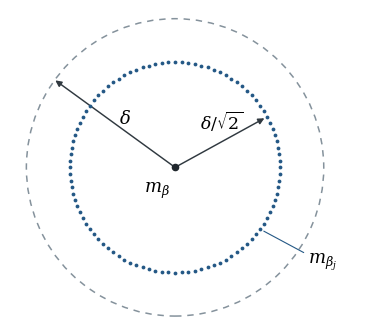

In [8]:
def draw_sampling_circle(out):
    plt.rcParams.update({'font.family': 'DejaVu Serif', 'mathtext.fontset': 'dejavuserif',
                         'pdf.fonttype': 42, 'ps.fonttype': 42})
    angle = 2*np.pi*np.arange(num_points)/num_points
    radius = 1/np.sqrt(2)
    means = radius * np.column_stack((np.cos(angle), np.sin(angle)))
    fig, ax = plt.subplots(figsize=(3.65, 3.25))
    ax.set_position((0.015, 0.015, 0.97, 0.97))
    ax.set_aspect('equal')
    ax.set_xlim(-1.11,1.25)
    ax.set_ylim(-1.06,1.06)
    ax.axis('off')
    ax.add_patch(Circle((0,0),1,fill=False,edgecolor='#85929c',ls=(0,(4.2,3.8)),lw=1.1))
    ax.scatter(*means.T, s=7.5, color='#245885', zorder=4, linewidths=0)
    def arrow(xy,shrink):
        ax.annotate('',xy=xy,xytext=(0,0),arrowprops=dict(arrowstyle='-|>',lw=1.05,
                    mutation_scale=9.0,color='#303940',shrinkA=1,shrinkB=shrink), zorder=2)
    ref = np.deg2rad(144)
    arrow((np.cos(ref),np.sin(ref)),0.5)
    arrow(means[8],2.3)
    ax.text(-.34,.33,r'$\delta$',fontsize=13,ha='center',va='center')
    ax.text(.31,.31,r'$\delta/\sqrt{2}$',fontsize=12.4,ha='center',va='center')
    ax.scatter(0,0,color='#20272d',s=20,zorder=5)
    ax.text(-.035,-.087,r'$m_{\beta}$',fontsize=13,ha='right',va='top')
    ax.annotate(r'$m_{\beta_j}$',xy=means[90],xytext=(.99,-.64),
                ha='center',va='center',fontsize=13,zorder=5,
                bbox={'boxstyle':'square,pad=0.09','fc':'white','ec':'none'},
                arrowprops={'arrowstyle':'-','lw':.8,'shrinkA':2,'shrinkB':3,'color':'#245885'})
    fig.savefig(out / 'wm_circle_sampling.pdf',facecolor='white',bbox_inches='tight',pad_inches=.025)
    plt.show()


draw_sampling_circle(output_dir)


## Run both experiments


1. **Comparison:** $\frac{\delta^2}{4}\left|\widehat d_{WM}^2-\widehat d_M^2\right|$.
2. **Recovery:** $\left|\frac{\delta^2}{4}\widehat d_{WM}^2-\|m_\alpha-m_\beta\|^2\right|$.

The cubic map is : $f(x_1,x_2)=(x_1+x_2^3,x_2-x_1^3)$.


In [9]:
def run_one_experiment(
    n_values,
    delta_list,
    cloud_std,
    cloud_size,
    num_points,
    factor_list,
):
    h_values = 1 / (n_values - 1)
    cov_h = (cloud_std ** 2) * np.eye(2)

    prototype_cloud = generate_centered_prototype_cloud(
        num_points_in_cloud=cloud_size,
        covariance_matrix=cov_h,
    )

    result_list = []
    pairs_list = []
    fmean_list = []
    covf_list = []
    mean_list = []

    for n, delta_i in zip(n_values, delta_list):
        S = generate_uniform_grid(n)

        result, pairs, fmean_dict, cov_f_dict = distance_approximation(
            S1=S,
            num_points=num_points,
            delta=delta_i,
            prototype_cloud=prototype_cloud,
            pairs=refined_pairs(n),
        )

        result_list.append(result)
        pairs_list.append(pairs)
        fmean_list.append(fmean_dict)
        covf_list.append(cov_f_dict)
        mean_list.append({idx: S[idx] for pair in pairs for idx in pair})
        print(f"  Completed grid {n} x {n}", flush=True)

    errors = []
    recovery_errors = []

    for result, factor, pairs, fmean_dict, cov_f_dict, delta_i, mean_dict in zip(
        result_list,
        factor_list,
        pairs_list,
        fmean_list,
        covf_list,
        delta_list,
        mean_list,
    ):
        err = compute_error_neighbors_only_mahalanobis(
            result=result,
            factor=factor,
            pairs=pairs,
            fmean_dict=fmean_dict,
            cov_f_dict=cov_f_dict,
            delta=delta_i,
        )
        errors.append(err)
        recovery_errors.append(compute_error_neighbors_only_euclidean_before_f(
            result=result, delta=delta_i, pairs=pairs, mean_dict=mean_dict
        ))

    return np.array(errors), np.array(recovery_errors), h_values


In [10]:
all_errors = []
all_recovery_errors = []

for run, seed in enumerate(prototype_seeds, start=1):
    np.random.seed(int(seed))
    print(f"Run {run}/{num_runs}; prototype seed {seed}", flush=True)
    errors_run, recovery_run, h_values = run_one_experiment(
        n_values=n_values,
        delta_list=delta_list,
        cloud_std=cloud_std,
        cloud_size=cloud_size,
        num_points=num_points,
        factor_list=factor_list,
    )
    all_errors.append(errors_run)
    all_recovery_errors.append(recovery_run)

all_errors = np.array(all_errors)
all_recovery_errors = np.array(all_recovery_errors)
assert all_errors.shape == all_recovery_errors.shape == (num_runs, len(n_values))
assert np.all(np.isfinite(all_errors)) and np.all(np.isfinite(all_recovery_errors))
print("Both experiments completed.")


Run 1/5; prototype seed 20261002


  Completed grid 17 x 17


  Completed grid 33 x 33


  Completed grid 65 x 65


  Completed grid 129 x 129


  Completed grid 257 x 257


... (21 outputs left out)

  Completed grid 65 x 65


  Completed grid 129 x 129


  Completed grid 257 x 257


Both experiments completed.


## Experiment 1: WM--Mahalanobis comparison




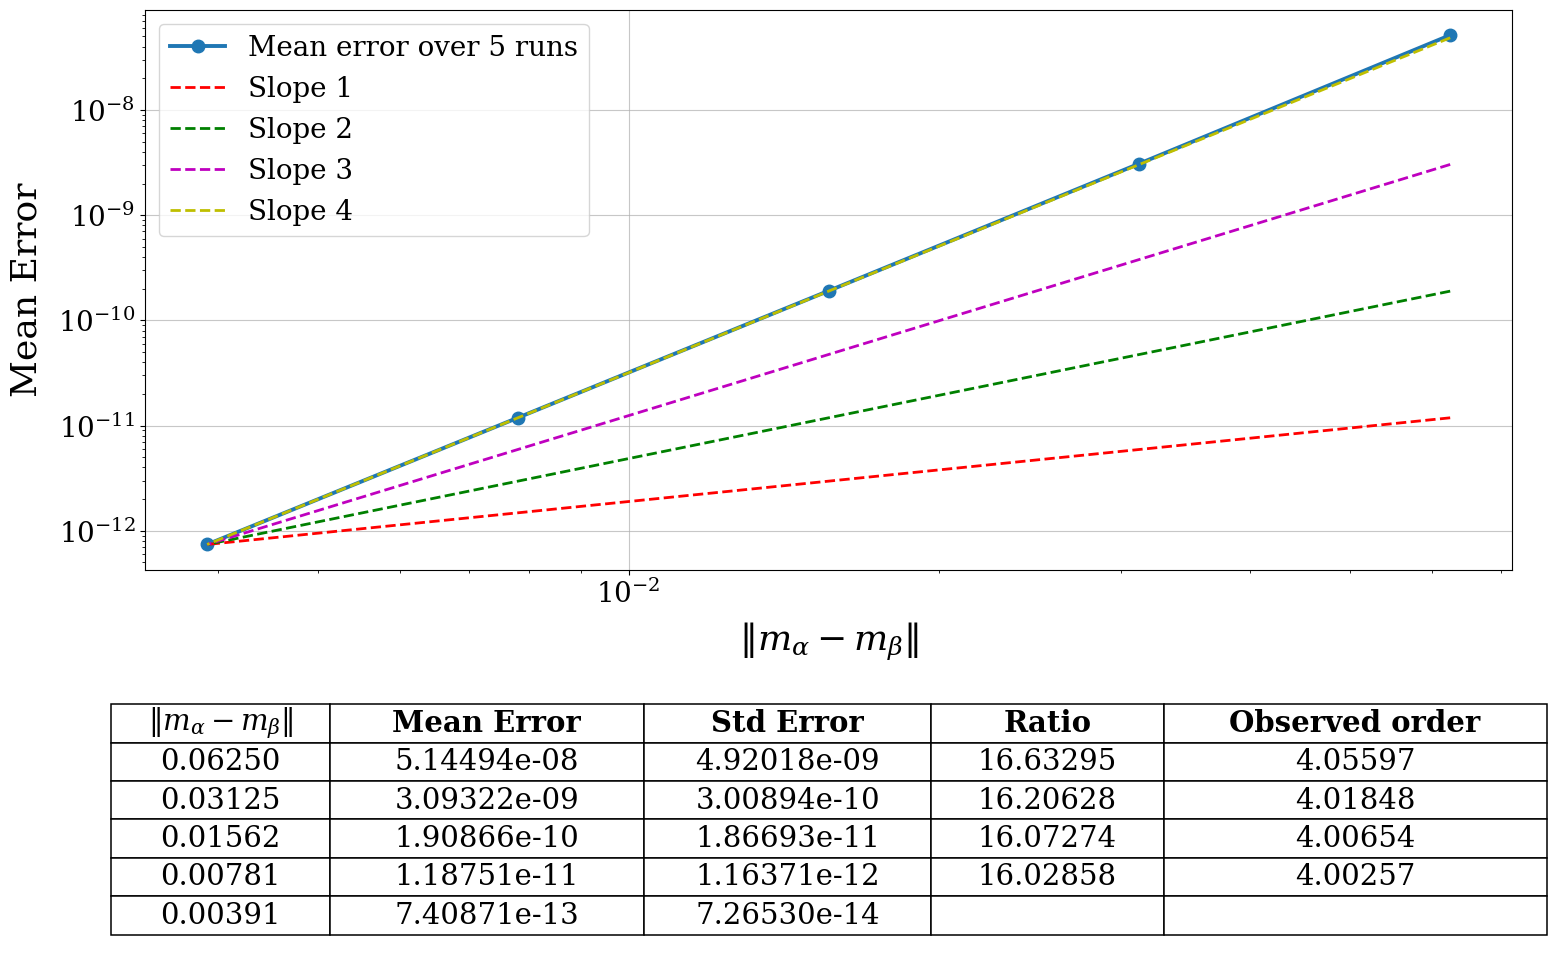

In [11]:
mean_errors = np.mean(all_errors, axis=0)
std_errors = np.std(all_errors, axis=0, ddof=1)
ratios, observed_orders = compute_ratio_and_order(mean_errors, h_values)

table_columns = [r"$\Vert m_\alpha-m_\beta\Vert$", "Mean Error", "Std Error", "Ratio", "Observed order"]
table_rows = make_table_rows(
    h_values=h_values,
    mean_values=mean_errors,
    std_values=std_errors,
    ratios=ratios,
    observed_orders=observed_orders,
)
save_plot_and_table_figure(
    h_values=h_values,
    mean_values=mean_errors,
    y_label="Mean Error",
    curve_label=f"Mean error over {num_runs} runs",
    table_columns=table_columns,
    table_rows=table_rows,
    curve_color=None,
    filename="wm_comparison.pdf",
)


## Experiment 2: latent-distance recovery


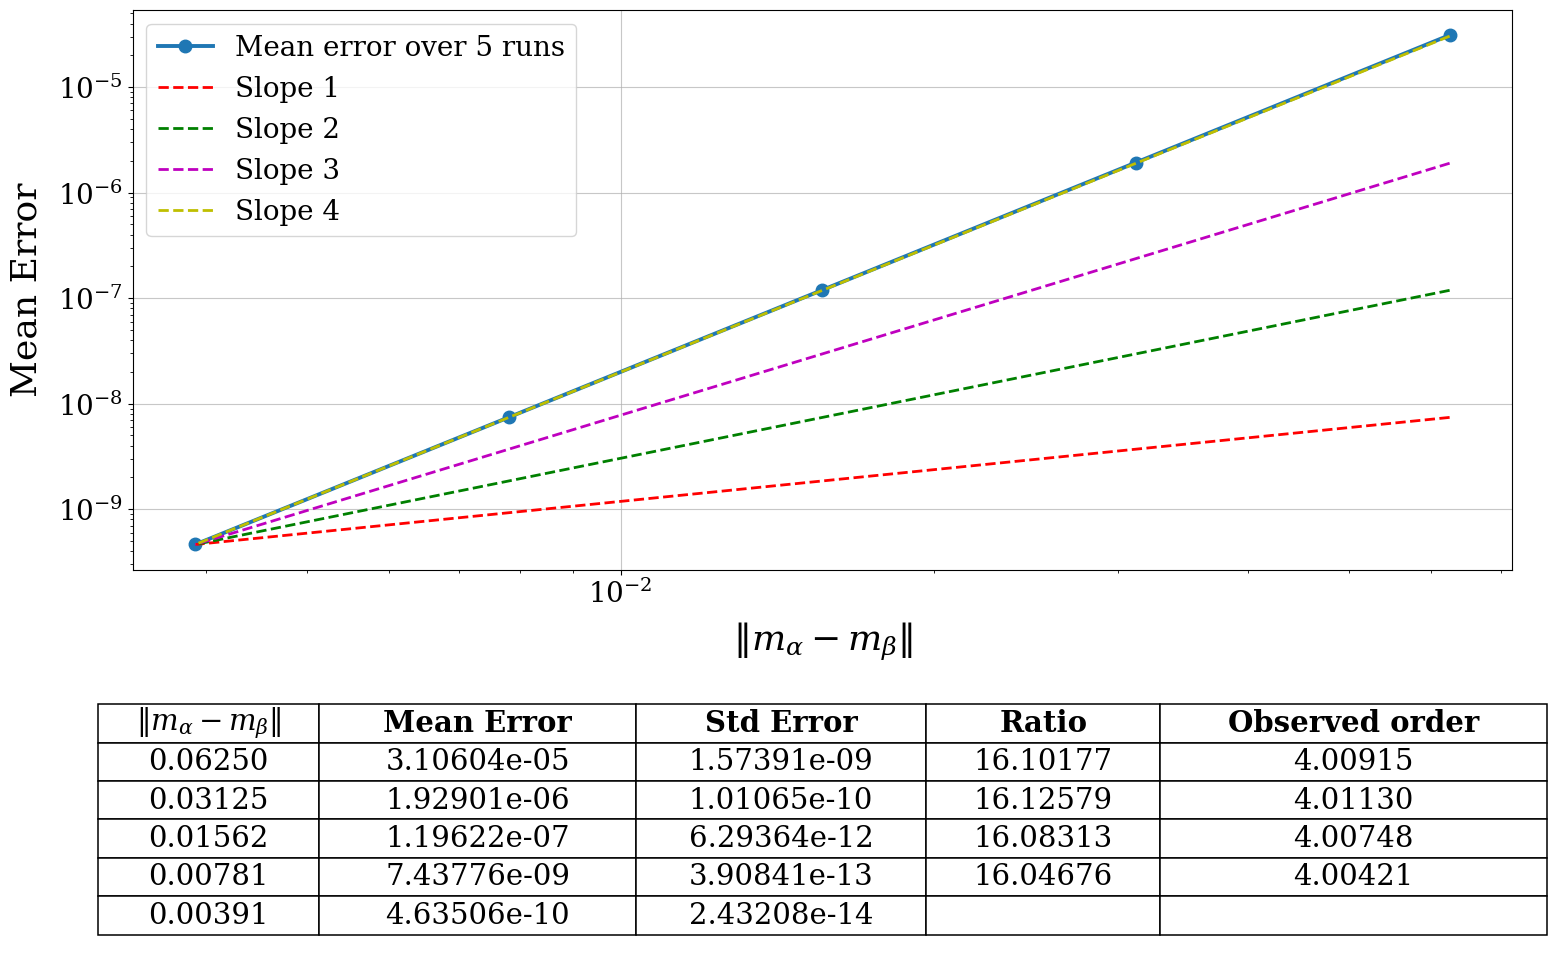

In [12]:
mean_errors = np.mean(all_recovery_errors, axis=0)
std_errors = np.std(all_recovery_errors, axis=0, ddof=1)
ratios, observed_orders = compute_ratio_and_order(mean_errors, h_values)

table_columns = [r"$\Vert m_\alpha-m_\beta\Vert$", "Mean Error", "Std Error", "Ratio", "Observed order"]
table_rows = make_table_rows(
    h_values=h_values,
    mean_values=mean_errors,
    std_values=std_errors,
    ratios=ratios,
    observed_orders=observed_orders,
)
save_plot_and_table_figure(
    h_values=h_values,
    mean_values=mean_errors,
    y_label="Mean Error",
    curve_label=f"Mean error over {num_runs} runs",
    table_columns=table_columns,
    table_rows=table_rows,
    curve_color=None,
    filename="wm_recovery.pdf",
)
